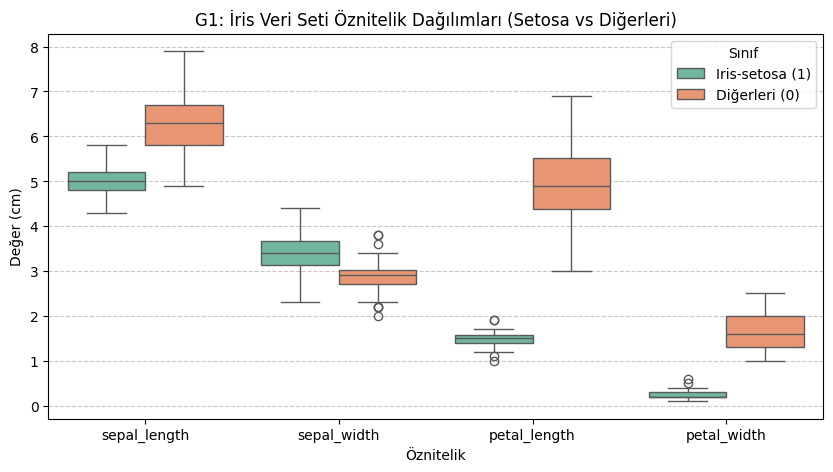

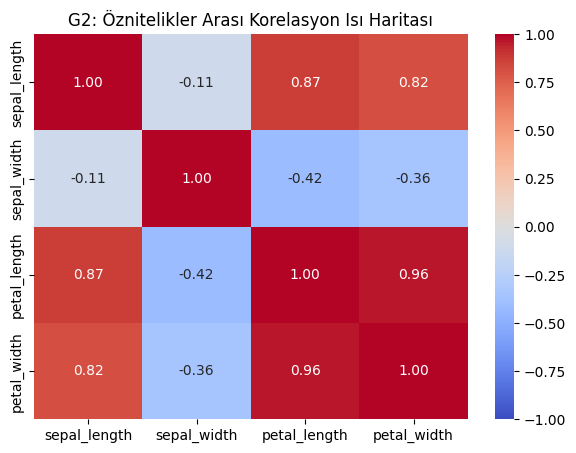


--- Tablo 4: Eğitim Setinden Çıkarılan Binarizasyon Eşikleri ---
sepal_length    5.844444
sepal_width     3.030000
petal_length    3.677778
petal_width     1.144444
dtype: float64

--- Tablo 6: Grid Search Tespit Tablosu ---
Optimum Ağırlık Vektörü (w): [-1  1 -1 -1]
Optimum Aktivasyon Eşiği (Theta): -0.5
Doğrulama (Validation) Başarısı: %96.67


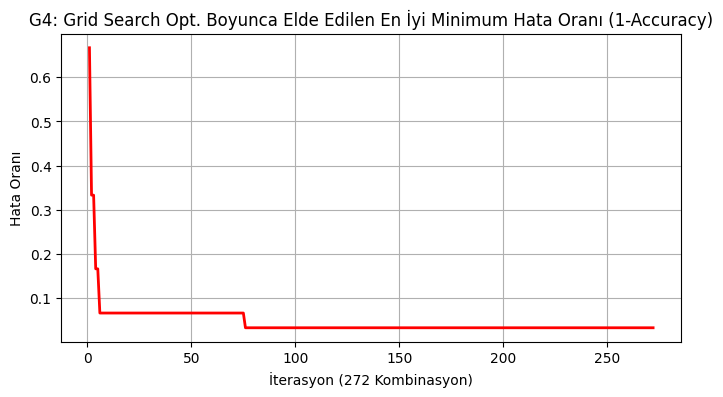

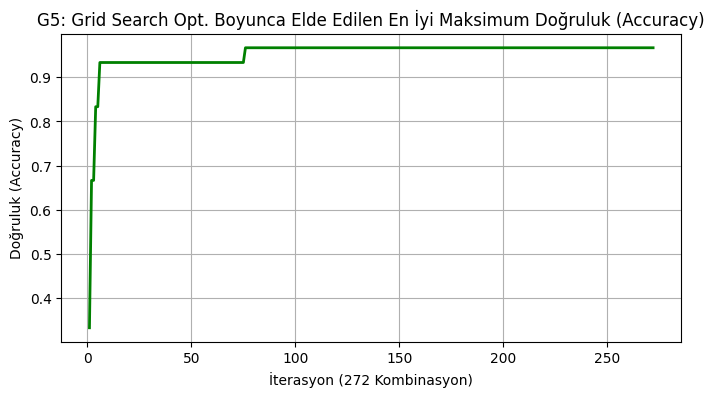

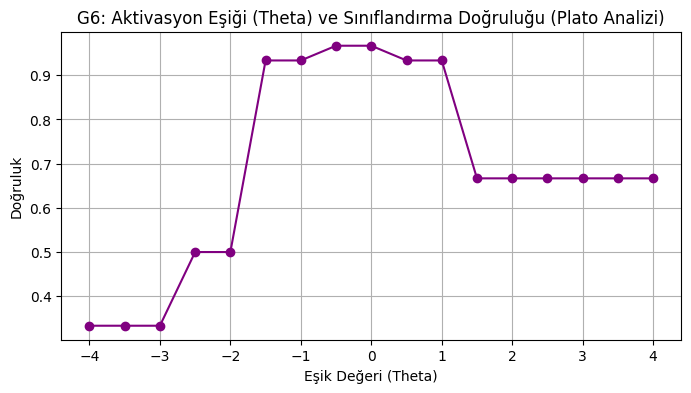


--- Tablo 7: Test Seti Ana Performans Metrikleri ---
Test Doğruluğu: %93.33
               precision    recall  f1-score   support

Diğerleri (0)       1.00      0.90      0.95        20
   Setosa (1)       0.83      1.00      0.91        10

     accuracy                           0.93        30
    macro avg       0.92      0.95      0.93        30
 weighted avg       0.94      0.93      0.93        30



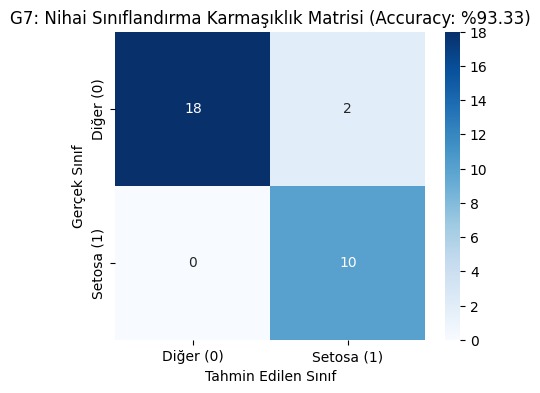


--- Tablo 8: Öznitelik Ablasyon (Duyarlılık) Testi Sonuçları ---
sepal_length Çıkarıldı -> Yeni Ağırlıklar (w): [ 1 -1 -1], Yeni Test Doğruluğu: %93.33
sepal_width Çıkarıldı -> Yeni Ağırlıklar (w): [-1 -1 -1], Yeni Test Doğruluğu: %93.33
petal_length Çıkarıldı -> Yeni Ağırlıklar (w): [-1  1 -1], Yeni Test Doğruluğu: %93.33
petal_width Çıkarıldı -> Yeni Ağırlıklar (w): [-1  1 -1], Yeni Test Doğruluğu: %93.33

--- Tablo 9: Yanlış Sınıflandırılan Örneklerin Orijinal Botanik Değerleri ---
    sepal_length  sepal_width  petal_length  petal_width  Gerçek  Tahmin
98           5.1          2.5           3.0          1.1       0       1
93           5.0          2.3           3.3          1.0       0       1

--- Tablo 10: Yanlış Sınıflandırılan Örneklerin Binarize Edilmiş Hallerinin Analizi ---
    sepal_length  sepal_width  petal_length  petal_width
98             0            0             0            0
93             0            0             0            0


In [2]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# 1. AYARLAR VE VERİ SETİ (Orijinal UCI Linkinden)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
col_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
df = pd.read_csv(url, header=None, names=col_names).dropna()

df_features = df.drop(columns=['target'])
y = pd.Series((df['target'] == 'Iris-setosa').astype(int))

# 2. G1 ve G2 GRAFİKLERİ
df_vis = df_features.copy()
df_vis['Sınıf'] = y.map({1: 'Iris-setosa (1)', 0: 'Diğerleri (0)'})

plt.figure(figsize=(10, 5))
df_melted = df_vis.melt(id_vars=['Sınıf'], var_name='Öznitelik', value_name='Değer (cm)')
sns.boxplot(x='Öznitelik', y='Değer (cm)', hue='Sınıf', data=df_melted, palette="Set2")
plt.title('G1: İris Veri Seti Öznitelik Dağılımları (Setosa vs Diğerleri)')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df_features.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('G2: Öznitelikler Arası Korelasyon Isı Haritası')
plt.show()

# 3. KATMANLI VERİ BÖLME (Stratified) VE BİNARİZASYON
X_train, X_temp, y_train, y_temp = train_test_split(df_features, y, test_size=0.40, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

means = X_train.mean()
print("\n--- Tablo 4: Eğitim Setinden Çıkarılan Binarizasyon Eşikleri ---")
print(means)

X_train_bin = (X_train >= means).astype(int).values
X_val_bin = (X_val >= means).astype(int).values
X_test_bin = (X_test >= means).astype(int).values
y_val_arr = y_val.values
y_test_arr = y_test.values

# 4. GRID SEARCH (Yazılımsal Optimizasyon Araması)
weights_space = list(itertools.product([-1, 1], repeat=4))
thresholds_space = np.linspace(-4, 4, 17)

best_val_acc = -1
best_w = None
best_theta = None
iterations = []
val_acc_history = []
val_error_history = [] # Hakemin Uyarısı: val_loss_history değiştirildi

iter_count = 0
current_best_acc = 0

for w in weights_space:
    w = np.array(w)
    for theta in thresholds_space:
        iter_count += 1
        z_val = np.dot(X_val_bin, w)
        pred_val = (z_val >= theta).astype(int)
        acc_val = accuracy_score(y_val_arr, pred_val)

        if acc_val > current_best_acc:
            current_best_acc = acc_val

        if acc_val > best_val_acc:
            best_val_acc = acc_val
            best_w = w
            best_theta = theta

        iterations.append(iter_count)
        val_acc_history.append(current_best_acc)
        val_error_history.append(1 - current_best_acc) # Hakemin Uyarısı

print(f"\n--- Tablo 6: Grid Search Tespit Tablosu ---")
print(f"Optimum Ağırlık Vektörü (w): {best_w}")
print(f"Optimum Aktivasyon Eşiği (Theta): {best_theta}")
print(f"Doğrulama (Validation) Başarısı: %{best_val_acc*100:.2f}")

# 5. G4, G5, G6 GRAFİKLERİ
plt.figure(figsize=(8,4))
plt.plot(iterations, val_error_history, color='red', linewidth=2) # Hakemin Uyarısı: val_error_history kullanıldı
plt.title("G4: Grid Search Opt. Boyunca Elde Edilen En İyi Minimum Hata Oranı (1-Accuracy)")
plt.xlabel("İterasyon (272 Kombinasyon)"); plt.ylabel("Hata Oranı")
plt.grid(True); plt.show()

plt.figure(figsize=(8,4))
plt.plot(iterations, val_acc_history, color='green', linewidth=2)
plt.title("G5: Grid Search Opt. Boyunca Elde Edilen En İyi Maksimum Doğruluk (Accuracy)")
plt.xlabel("İterasyon (272 Kombinasyon)"); plt.ylabel("Doğruluk (Accuracy)")
plt.grid(True); plt.show()

theta_accs = [accuracy_score(y_val_arr, (np.dot(X_val_bin, best_w) >= t).astype(int)) for t in thresholds_space]
plt.figure(figsize=(8,4))
plt.plot(thresholds_space, theta_accs, marker='o', color='purple')
plt.title("G6: Aktivasyon Eşiği (Theta) ve Sınıflandırma Doğruluğu (Plato Analizi)")
plt.xlabel("Eşik Değeri (Theta)"); plt.ylabel("Doğruluk")
plt.grid(True); plt.show()

# 6. TEST BAŞARISI VE G7
z_test = np.dot(X_test_bin, best_w)
y_pred_test = (z_test >= best_theta).astype(int)
test_acc = accuracy_score(y_test_arr, y_pred_test)

print(f"\n--- Tablo 7: Test Seti Ana Performans Metrikleri ---")
print(f"Test Doğruluğu: %{test_acc*100:.2f}")
print(classification_report(y_test_arr, y_pred_test, target_names=["Diğerleri (0)", "Setosa (1)"]))

cm = confusion_matrix(y_test_arr, y_pred_test)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Diğer (0)", "Setosa (1)"], yticklabels=["Diğer (0)", "Setosa (1)"])
plt.title(f"G7: Nihai Sınıflandırma Karmaşıklık Matrisi (Accuracy: %{test_acc*100:.2f})")
plt.ylabel('Gerçek Sınıf'); plt.xlabel('Tahmin Edilen Sınıf')
plt.show()

# 7. ABLASYON ANALİZİ
print("\n--- Tablo 8: Öznitelik Ablasyon (Duyarlılık) Testi Sonuçları ---")
for idx, col in enumerate(df_features.columns):
    X_val_abl = np.delete(X_val_bin, idx, 1)
    X_test_abl = np.delete(X_test_bin, idx, 1)
    b_val, b_w, b_th = -1, None, None
    for w in itertools.product([-1, 1], repeat=3):
        for t in thresholds_space:
            acc = accuracy_score(y_val_arr, (np.dot(X_val_abl, np.array(w)) >= t).astype(int))
            if acc > b_val:
                b_val = acc
                b_w, b_th = np.array(w), t
    t_acc = accuracy_score(y_test_arr, (np.dot(X_test_abl, b_w) >= b_th).astype(int))
    print(f"{col} Çıkarıldı -> Yeni Ağırlıklar (w): {b_w}, Yeni Test Doğruluğu: %{t_acc*100:.2f}")

# 8. HATA ANALİZİ
errors = y_test_arr != y_pred_test
if errors.sum() > 0:
    err_df = X_test[errors].copy()
    err_df['Gerçek'] = y_test_arr[errors]
    err_df['Tahmin'] = y_pred_test[errors]
    print("\n--- Tablo 9: Yanlış Sınıflandırılan Örneklerin Orijinal Botanik Değerleri ---")
    print(err_df)

    print("\n--- Tablo 10: Yanlış Sınıflandırılan Örneklerin Binarize Edilmiş Hallerinin Analizi ---")
    print(pd.DataFrame(X_test_bin[errors], columns=df_features.columns, index=err_df.index))